# Сравнение детекторов разладок: CPOP, регрессионный PELT, trend filtering и RBF

Четыре предложенных подхода реализованы в отдельных скриптах. Регрессионный PELT показан в двух вариантах — линейном и квадратичном. В качестве исходного метода добавлены прямоугольники: всего **шесть вариантов** в едином сравнении.

Исследуем, какие изменения обнаруживает каждый критерий: изломы тренда, смену кривизны, среднего и дисперсии. Отдельно проверяем ложные срабатывания на шуме, единичном выбросе и стационарных колебаниях. Подбор параметров выполняется на независимом калибровочном наборе; тестовые сигналы и реальные МЭГ-записи в подборе не участвуют.

Данные берутся через существующие загрузчики `utils/data_loading.py`. Ноутбук содержит только вызовы и представление результатов; алгоритмы, метрики и графики находятся в `.py`-файлах.

**Запуск:** `python -m pip install -r requirements.txt`, затем Restart & Run All. Новая зависимость — `clarabel`, решатель выпуклой задачи trend filtering. `INCLUDE_MNE=False` оставляет реальные примеры только из Excel. Первый запуск MNE использует/загружает стандартный кеш, как в EDA. Сравнение выполняется на CPU и может занять несколько минут.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT_ROOT = next(
    parent for parent in (Path.cwd(), *Path.cwd().parents)
    if (parent / "src").is_dir() and (parent / "utils" / "paths.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from utils.paths import DATA_DIR, EXPERIMENTS_DIR
from utils import breakpoint_comparison as bench
from utils.meg_eda import scroll_table

%matplotlib inline
plt.rcParams.update({"figure.dpi": 95, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
INCLUDE_MNE = True
MIN_DURATION_S = 0.03
CANDIDATE_GRID_S = 0.01
MATCH_TOLERANCE_S = 0.02
OUTPUT_DIR = EXPERIMENTS_DIR / "breakpoint_comparison"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


## 1. Модели, реализация и смысл точности

| Подход | Отдельный скрипт | Оптимизируемый критерий | Стыки |
|---|---|---|---|
| CPOP | `src/cpop_segmentation.py` | RSS/n + β·число изломов | Непрерывная кусочно-линейная кривая |
| PELT-linear / quadratic | `src/pelt_regression.py` | Сумма минимальных сегментных RSS/n + β·число границ | Полиномы степени 1/2 независимы; скачки допустимы |
| Trend-filter-L1 | `src/trend_filtering.py` | 0.5·RSS/n + λ·сумма абсолютных вторых разностей | Оценка тренда с редкими изменениями наклона |
| PELT-RBF | `src/pelt_rbf.py` | Сумма внутрисегментных дисперсий в RKHS/n + β·число границ | Модель изменения распределения |
| Прямоугольники | ранее реализованная стоимость + общая PELT-динамика | Нормированная площадь + β·число границ | Покрытие диапазона амплитуд |

Перед первыми четырьмя методами ряд **глобально** центрируется и делится на std. Обратное преобразование возвращает аппроксимацию в исходные единицы. У прямоугольников сохраняется нормировка на общий диапазон амплитуд.

**CPOP.** Реализована динамика квадратичных функций от значения тренда в последнем узле. Нижняя огибающая вычисляется аналитически по пересечениям парабол; значения амплитуды не дискретизируются. Используется функциональное отсечение из статьи, `h=0`; дополнительное неравенственное отсечение авторов опущено. Это сохраняет точность, но может увеличить время и память.

**PELT.** Общая динамика в `src/breakpoint_common.py` учитывает минимальную длину сегмента с отложенным отсечением. Для полиномов используются устойчивые локальные ортогональные базисы и префиксные суммы; для RBF — точная гауссова матрица Грама и двумерные префиксные суммы. RBF требует $O(n^2)$ памяти и подготовки. Параметр ядра — обратная медиана квадратов попарных расстояний; если медиана нулевая, берётся медиана положительных расстояний, а для постоянного ряда — 1.

**Сетка.** В эксперименте все методы получают кандидаты приблизительно через 10 мс и минимум сегмента около 30 мс. Все отсчёты входят в стоимость; прореживаются только допустимые положения границ. CPOP и три PELT-варианта находят минимум **на указанной сетке** с учётом ограничений, в пределах точности арифметики. `jump=1` в отдельных функциях включает все допустимые позиции. Прямоугольники сравниваются на той же сетке; при `jump=1` критерий совпадает с прежним модулем.

**Trend filtering.** Сам выпуклый оптимум вычисляется на всех отсчётах. Для представления границ: активные вторые разности выше `1e-5` нормированных единиц привязываются к сетке, затем сохраняются самые сильные совместимые изменения с интервалом `min_size`. Это **явная эвристика извлечения границ**, а не ограничение выпуклой задачи. Оценка тренда после этого не меняется. Число исходных узлов и итоговых границ сохраняется раздельно; статус решателя, KKT-невязка и двойственный разрыв доступны в диагностике.

В RBF и прямоугольниках линия среднего сегмента служит только для отображения. Её RSS не является их целевой функцией. Численные значения разных целевых функций не используются для ранжирования методов.

## 2. Синтетические механизмы и независимые наборы

Восемь сценариев:

- `slope` — два излома непрерывного линейного тренда;
- `quadratic` — два изменения кривизны при непрерывных значении и первой производной;
- `mean` — скачки среднего;
- `variance` — изменение дисперсии при нулевом среднем;
- `ar_slope` — изломы на фоне автокоррелированного AR(1)-шума;
- `noise` — стационарный гауссов шум без границ;
- `spike` — одиночный выброс на прямой без смены режима;
- `oscillation` — стационарные колебания 10 Гц без смены режима.

В последних трёх сценариях разладок по определению нет. В `oscillation` колебание считается фоновой ритмикой, а целевой тренд нулевой; это специально выбранный отрицательный контроль для задачи выделения устойчивых режимов.

Калибровка: seed=100, **240 отсчётов**, два повтора каждого механизма — 16 рядов. Тест: seed=1000, **300 отсчётов**, три повтора — 24 новых ряда. Частота 200 Гц. Изменение длины дополнительно проверяет перенос настройки. На графике — первые тестовые повторы, выбранные до просмотра результатов детекции.

Калибровка: 16 рядов; тест: 24 рядов


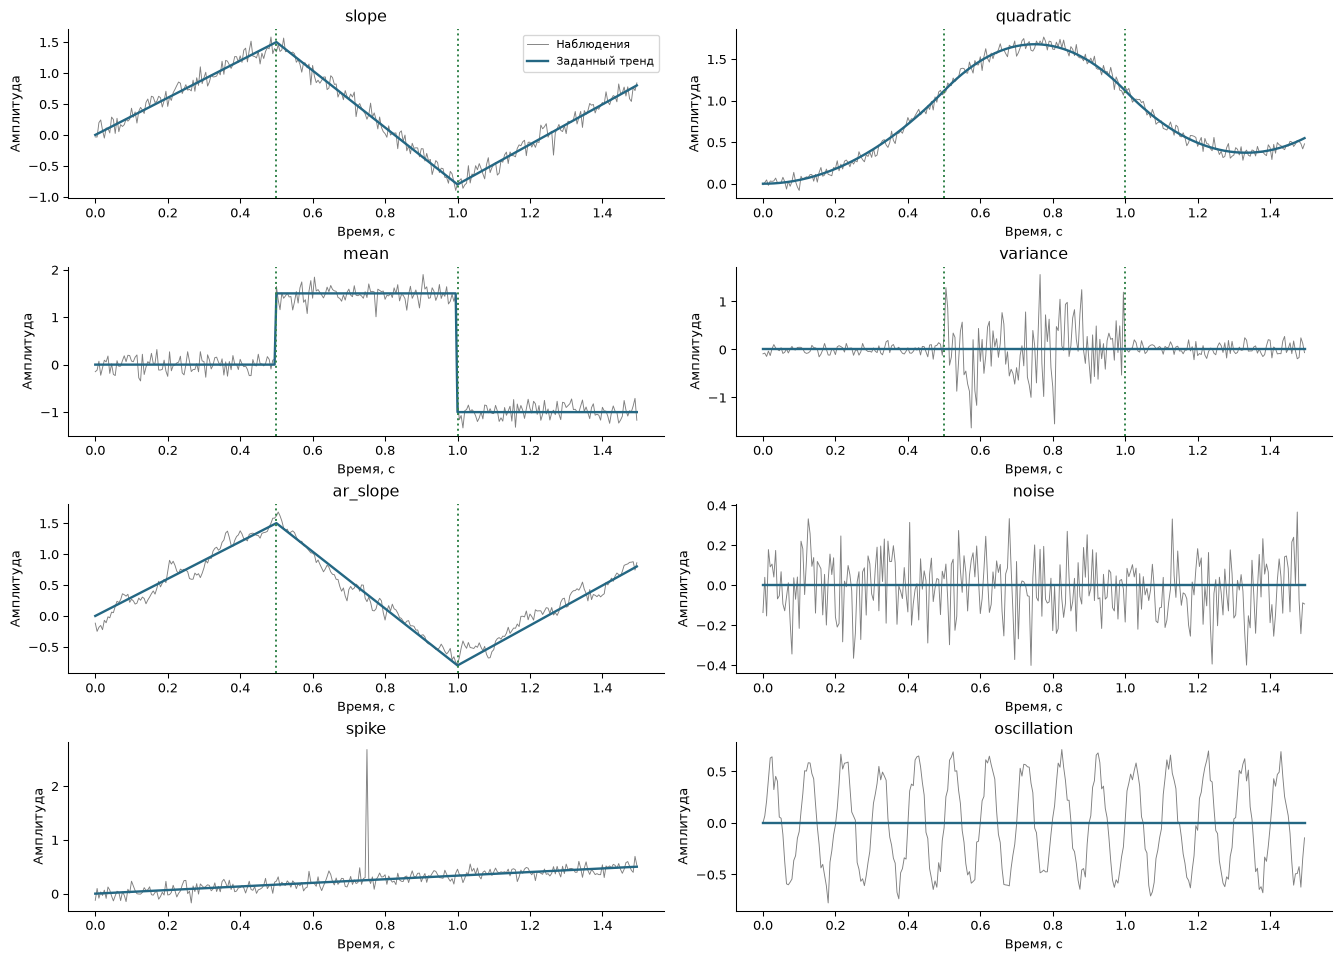

In [2]:
calibration_cases = bench.synthetic_suite(seed=100, n=240, repeats=2, sfreq=200.)
test_cases = bench.synthetic_suite(seed=1000, n=300, repeats=3, sfreq=200.)
print(f"Калибровка: {len(calibration_cases)} рядов; тест: {len(test_cases)} рядов")
bench.plot_scenarios(test_cases)
plt.show()


## 3. Отдельный подбор параметров

Каждый метод получает собственную сетку штрафа. Выбирается максимальный **средний F1 с одинаковым весом каждого сценария**; при равенстве предпочтительнее меньше ложных границ/с, затем более сильная регуляризация. F1 считается с допуском 20 мс и взаимно однозначным сопоставлением: несколько предсказаний около одной истинной границы не получают несколько правильных совпадений. Для пустой истины и пустого предсказания F1=1, для пустой истины с любым предсказанием — 0. В отчёте положительные и отрицательные сценарии дополнительно разделяются.

**Параметр trend filtering в этом сравнении — `c`, а не β или `strength`:**

$$\lambda = c\,\widehat{\sigma}\sqrt{n},\qquad
\widehat{\sigma}=\frac{\operatorname{MAD}(D^2z)}{0.67448975\sqrt{6}}.$$

Это шумовая параметризация коэффициента при L1-штрафе в критерии со средним RSS. Множитель $\sqrt{6}$ соответствует дисперсии вторых разностей независимого шума. На коррелированном/фильтрованном сигнале это эвристическая оценка масштаба, а не точная оценка шумовой дисперсии. Применённый λ и эффективный λ/λmax записываются для каждого ряда. Отдельный модуль также позволяет напрямую задать `lambda_value` или `strength=λ/λmax`.

Оптимальные параметры относятся к **выбранной смеси сценариев**, а не являются универсальными настройками МЭГ. Тестовый набор и реальные записи не используются в этой процедуре.

,Выбранный параметр
CPOP,0.120
PELT-linear,0.120
PELT-quadratic,0.400
Trend-filter-L1,0.400
PELT-RBF,0.035
Rectangles,0.060


method,parameter,calibration_macro_f1,calibration_fp_per_s
CPOP,0.003,0.30743,7.636
CPOP,0.01,0.37222,4.4456
CPOP,0.035,0.45833,3.0335
CPOP,0.12,0.6875,0.20921
CPOP,0.4,0.5,0.20921
PELT-RBF,0.003,0.17895,10.774
PELT-RBF,0.01,0.40278,5.387
PELT-RBF,0.035,0.54167,1.4121
PELT-RBF,0.12,0.375,0.47071
PELT-linear,0.003,0.32098,7.9498


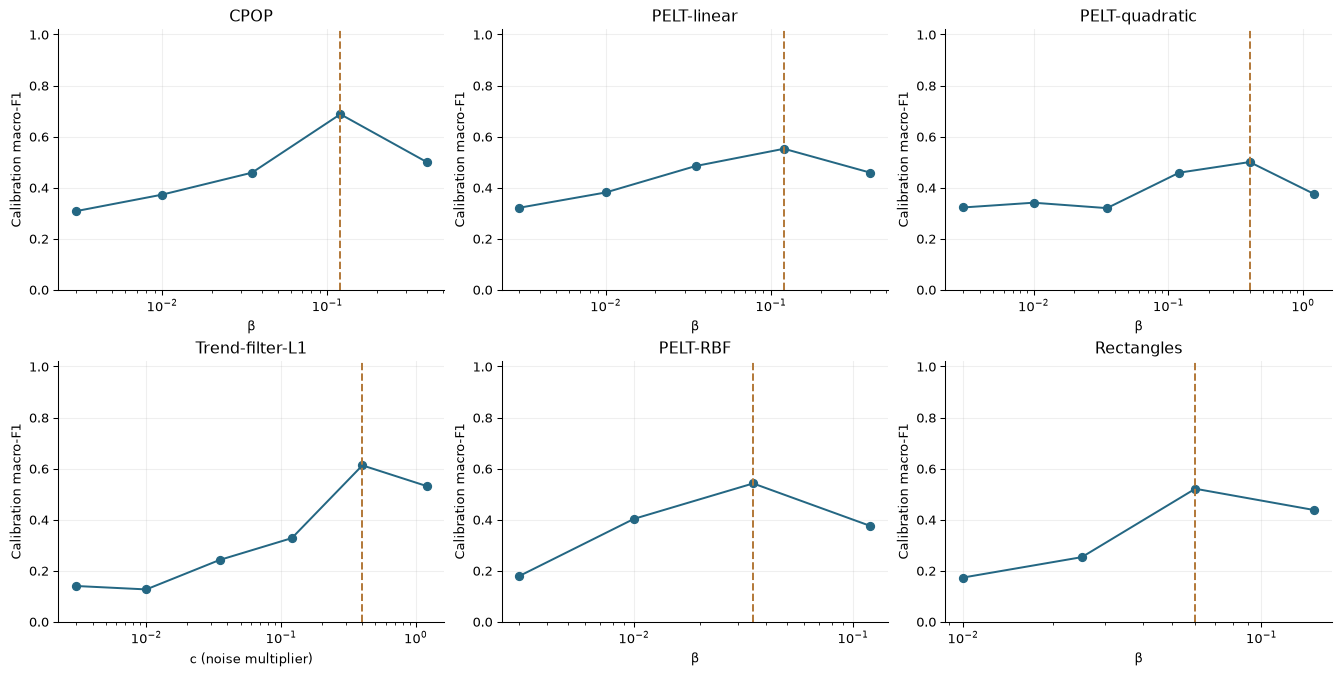

In [3]:
selected_parameters, calibration_scores, calibration_predictions = bench.calibrate(
    calibration_cases, min_duration=MIN_DURATION_S, grid_seconds=CANDIDATE_GRID_S,
    tolerance_seconds=MATCH_TOLERANCE_S,
)
display(pd.Series(selected_parameters, name="Выбранный параметр").reindex(bench.METHODS).to_frame())
display(scroll_table(calibration_scores, max_height=380))
bench.plot_calibration(calibration_scores, selected_parameters)
plt.show()


## 4. Независимая проверка

После выбора параметры фиксируются. Помимо F1 считаем:

- ошибку времени только для сопоставленных границ; отсутствие совпадений оставляет NaN;
- частоту ложных границ в секунду на отрицательных контролях;
- долю отрицательных рядов, на которых метод не поставил ни одной границы;
- время одного вызова, включая подготовку его стоимости/решателя;
- для моделей тренда — RMSE относительно заданной кривой, нормированную на std наблюдаемого ряда.

Среднее время — ориентировочный замер на этом компьютере, без повторных измерений и доверительного интервала. Эксперимент небольшой; три повтора не дают убедительного статистического ранжирования близких результатов. Варианты с разными целевыми механизмами нужно сравнивать по строкам сценариев.

,positive_f1,timing_mae_ms,negative_fp_per_s,negative_zero_detection_fraction,mean_runtime_s
method,,,,,
CPOP,0.500000,6.111111,0.000000,1.000000,0.874040
PELT-linear,0.500000,8.333333,0.000000,1.000000,0.003445
PELT-quadratic,0.133333,6.666667,0.000000,1.000000,0.005826
Trend-filter-L1,0.386667,12.500000,0.000000,1.000000,0.002569
PELT-RBF,0.488889,2.777778,0.520253,0.666667,0.003917
Rectangles,0.431111,2.142857,0.743218,0.444444,0.002343


method,CPOP,PELT-linear,PELT-quadratic,Trend-filter-L1,PELT-RBF,Rectangles
scenario,,,,,,
slope,1.0,1.000000,0.000000,1.000000,0.000000,0.000000
quadratic,0.0,0.000000,0.000000,0.000000,0.444444,0.222222
mean,0.5,0.666667,0.000000,0.000000,1.000000,1.000000
variance,0.0,0.000000,0.000000,0.000000,1.000000,0.933333
ar_slope,1.0,0.833333,0.666667,0.933333,0.000000,0.000000
noise,1.0,1.000000,1.000000,1.000000,1.000000,0.333333
spike,1.0,1.000000,1.000000,1.000000,0.000000,0.000000
oscillation,1.0,1.000000,1.000000,1.000000,1.000000,1.000000


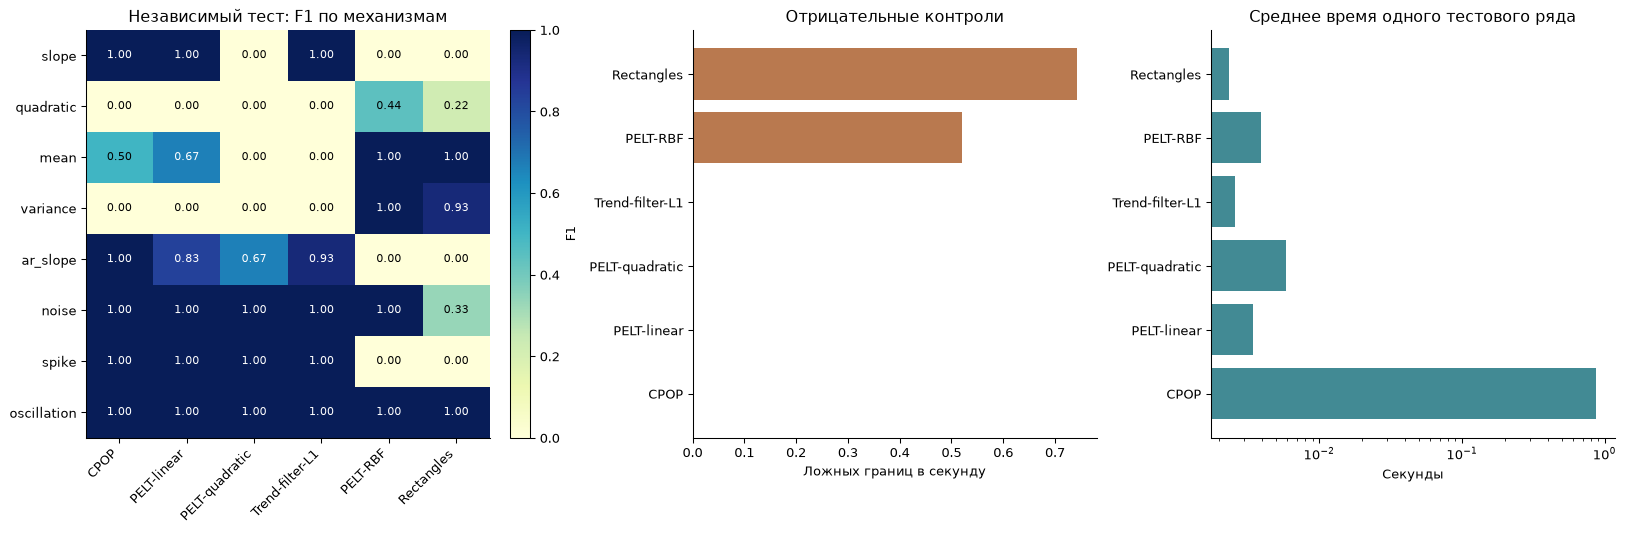

In [4]:
test_metrics, test_results = bench.compare_cases(
    test_cases, selected_parameters, min_duration=MIN_DURATION_S,
    grid_seconds=CANDIDATE_GRID_S, tolerance_seconds=MATCH_TOLERANCE_S,
)
overall, by_scenario = bench.summary_tables(test_metrics)
display(overall)
display(by_scenario.pivot(index="scenario", columns="method", values="f1").reindex(index=bench.SCENARIOS, columns=bench.METHODS))
summary_figure = bench.plot_test_summary(by_scenario, overall)
summary_figure.savefig(OUTPUT_DIR / "synthetic_summary.png", dpi=130, bbox_inches="tight")
plt.show()


In [5]:
trend_methods = ["CPOP", "PELT-linear", "PELT-quadratic", "Trend-filter-L1"]
trend_scenarios = ["slope", "quadratic", "ar_slope"]
trend_quality = test_metrics.loc[
    test_metrics.method.isin(trend_methods) & test_metrics.scenario.isin(trend_scenarios)
].groupby(["scenario", "method"]).trend_rmse_normalized.mean().unstack()
display(trend_quality)


method,CPOP,PELT-linear,PELT-quadratic,Trend-filter-L1
scenario,,,,
ar_slope,0.086561,0.117422,0.207462,0.125915
quadratic,0.255612,0.255638,0.458532,0.201274
slope,0.023205,0.025576,0.178140,0.155240


В этой таблице RMSE характеризует восстановление кривой, а F1 — расположение границ. Низкая ошибка кривой может сочетаться с неправильным числом/положением границ. Например, более гибкий полином способен аппроксимировать несколько режимов одним сегментом; линейная модель может добавлять узлы для приближения гладкой кривизны.

## 5. Сигналы, границы и аппроксимации

Показаны первые тестовые повторы четырёх заранее выбранных сценариев: изломы, кривизна, дисперсия и стационарная ритмика. Оранжевый пунктир — найденные границы, зелёный — истинные. Последняя точка `n` служит концом записи и не изображается как разладка.

Для RBF и прямоугольников синяя линия означает среднее сегмента; для остальных методов — оптимизированную оценку тренда. В trend filtering могут оставаться дополнительные слабые узлы, исключённые только из списка сообщаемых границ.

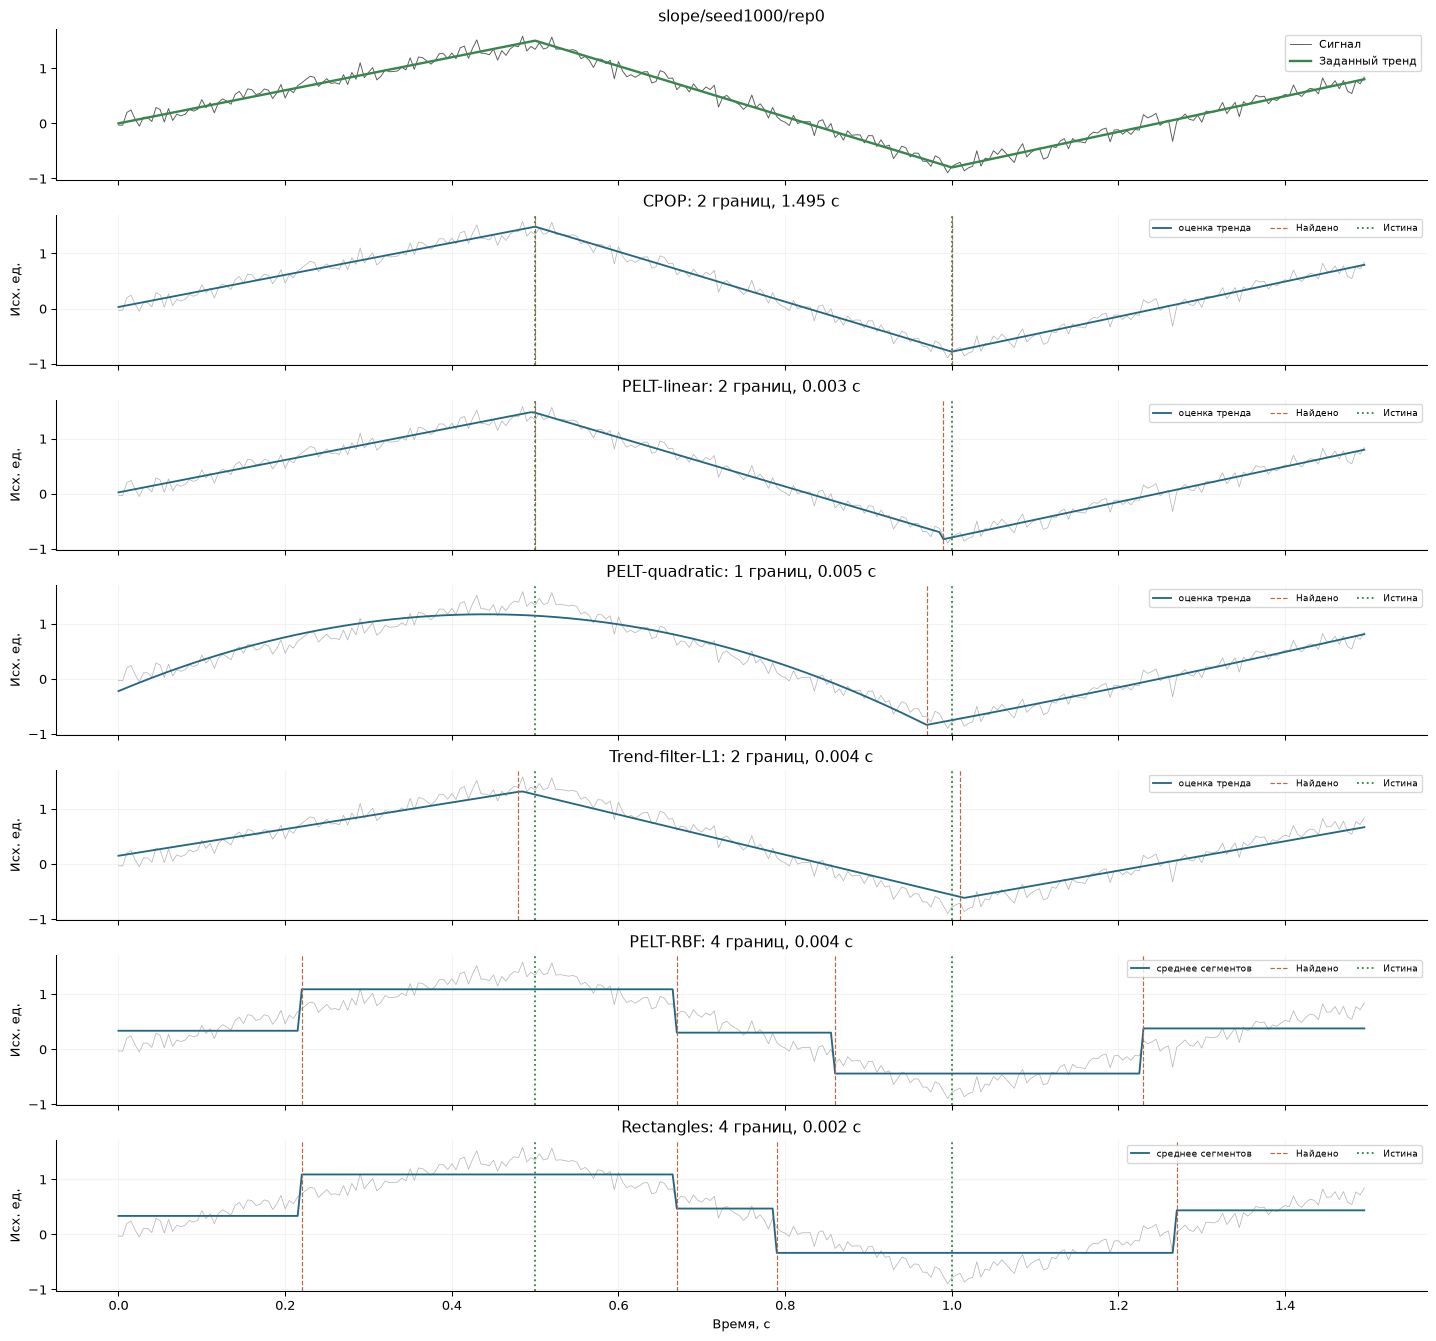

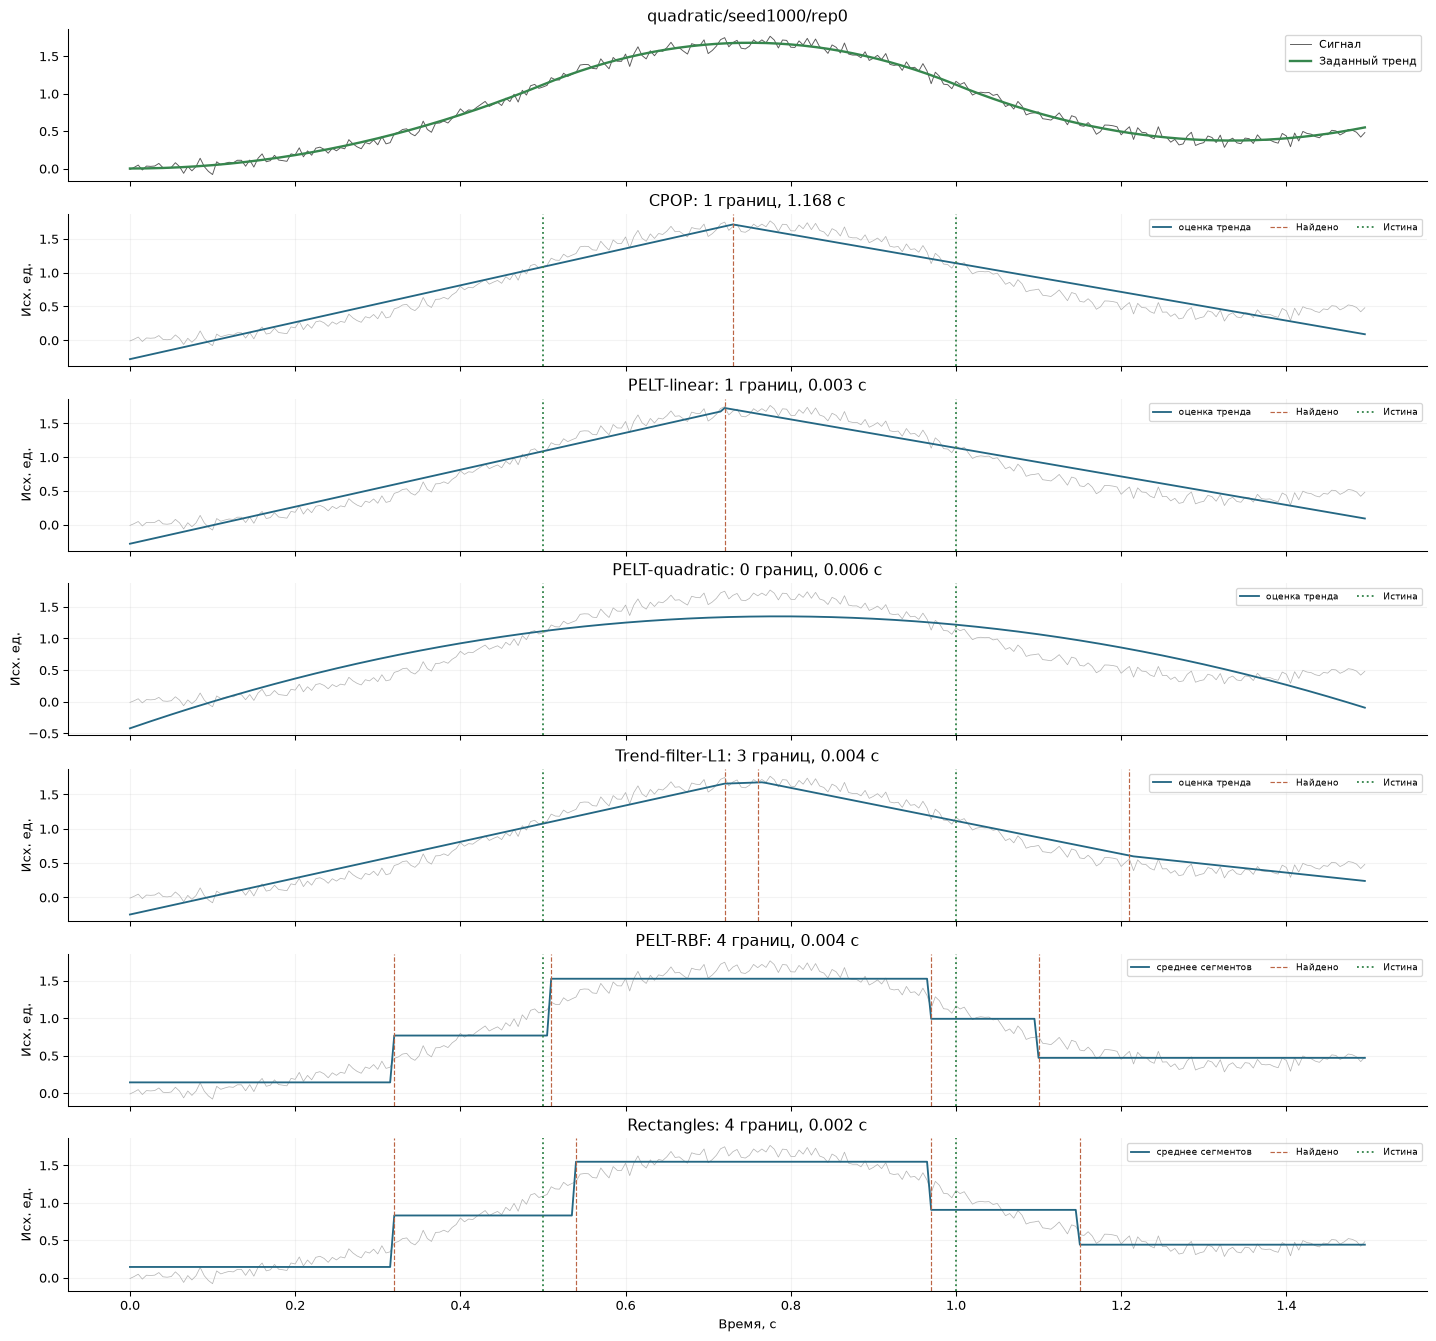

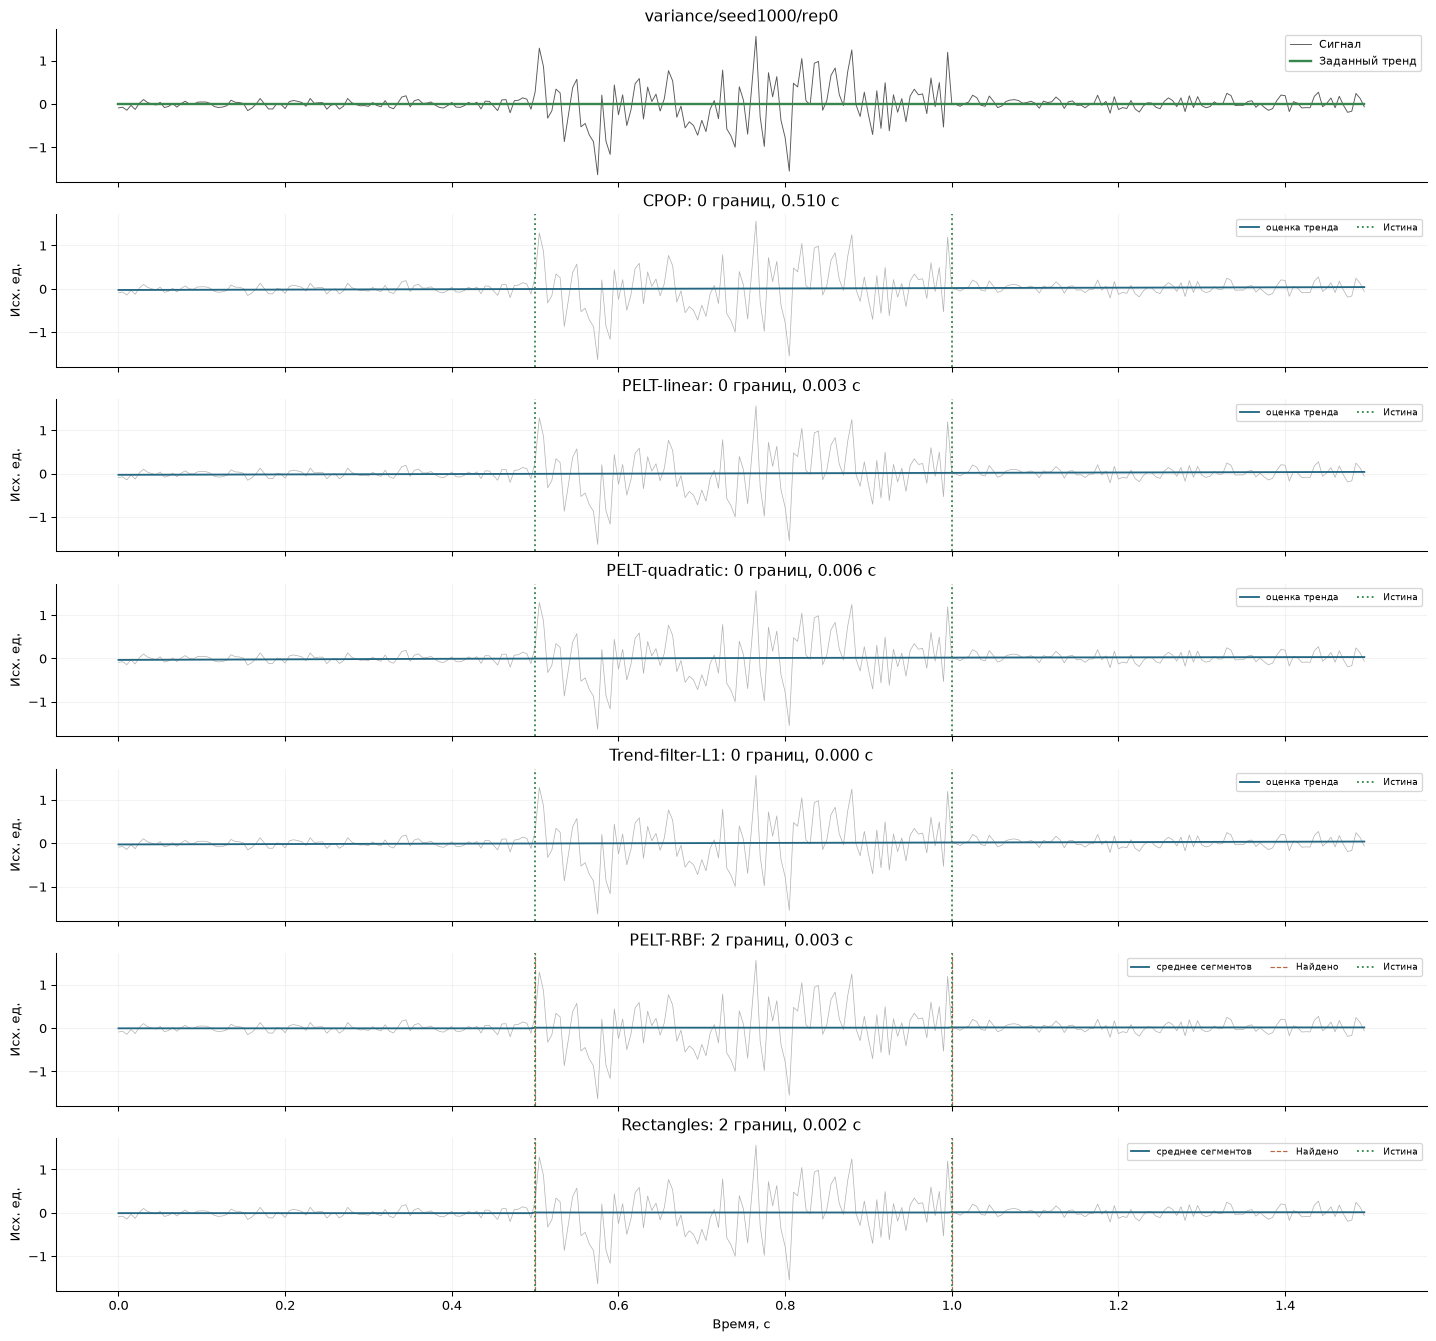

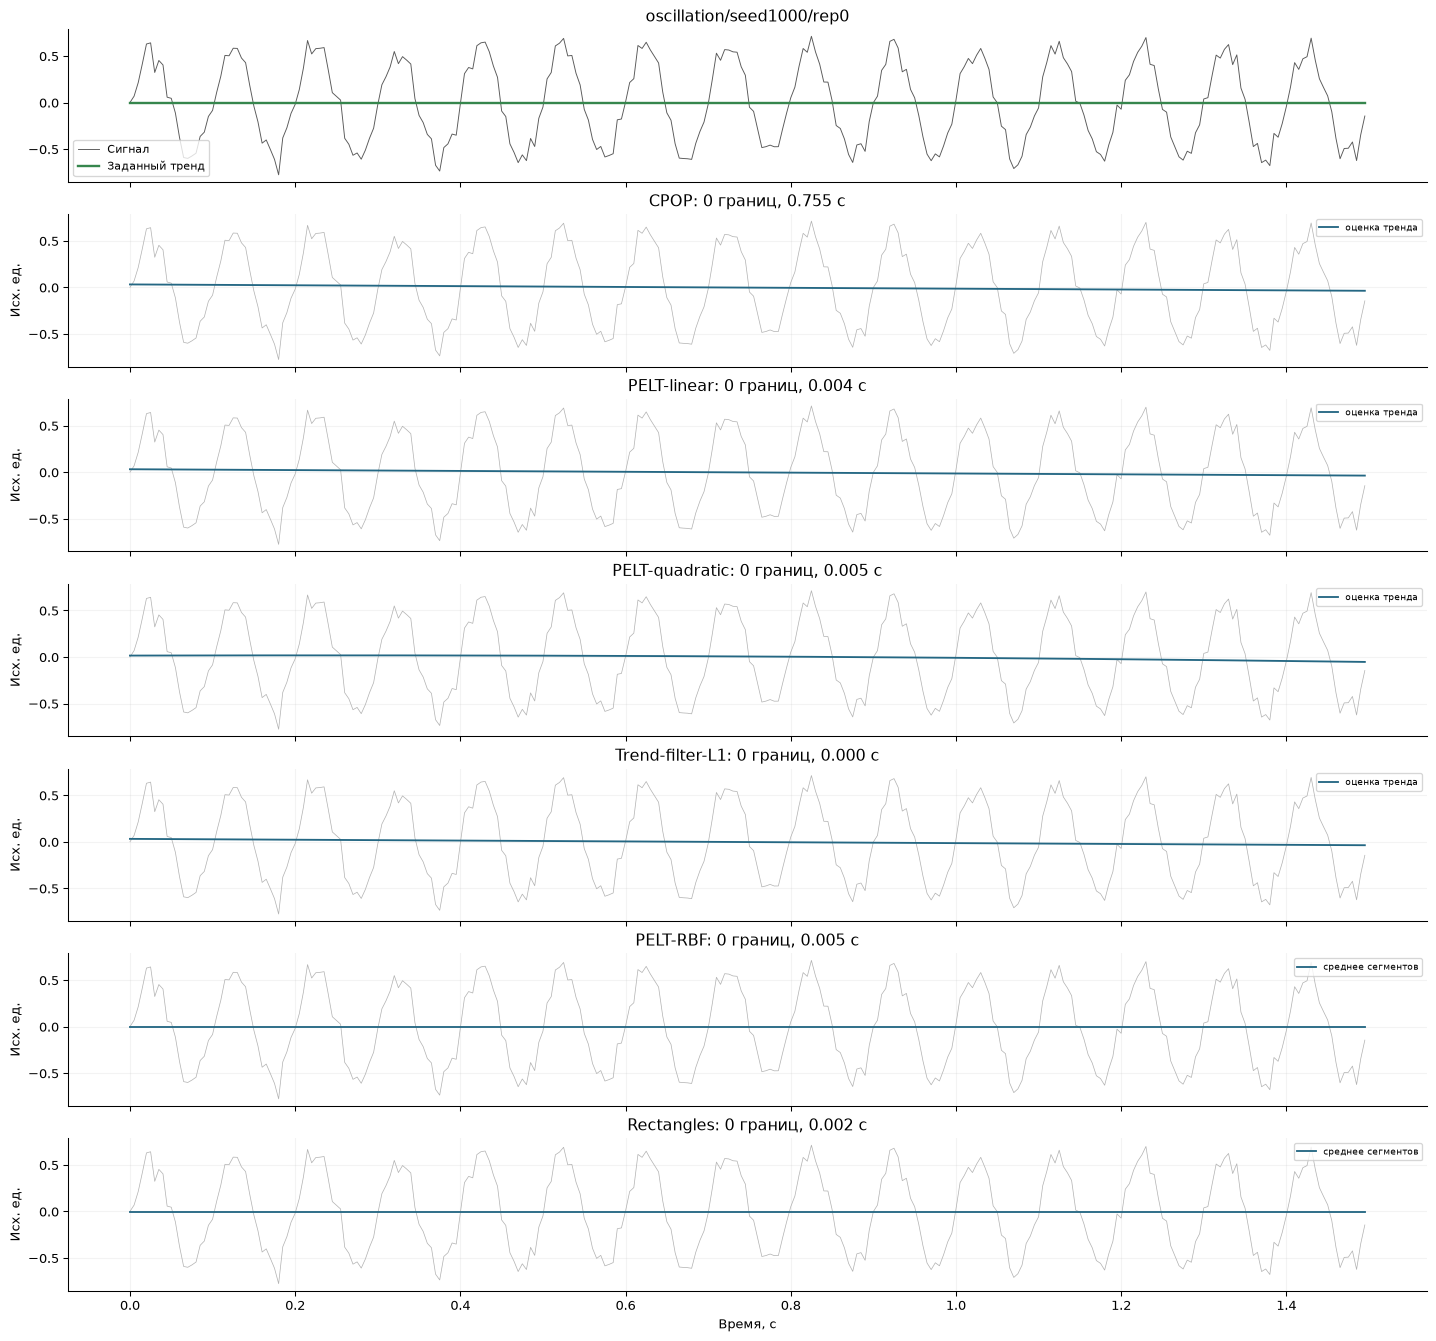

In [6]:
for scenario in ["slope", "quadratic", "variance", "oscillation"]:
    case = next(c for c in test_cases if c.scenario == scenario)
    bench.plot_case_comparison(case, test_results[case.case_id])
    plt.show()


## 6. Чувствительность к допуску совпадения

Параметры методов не меняются. Повторно оцениваем те же границы при допуске 10, 20 и 40 мс. Рост F1 при расширении допуска показывает ошибки локализации, но сам по себе не означает улучшения детектора. На этой диаграмме только положительные сценарии.

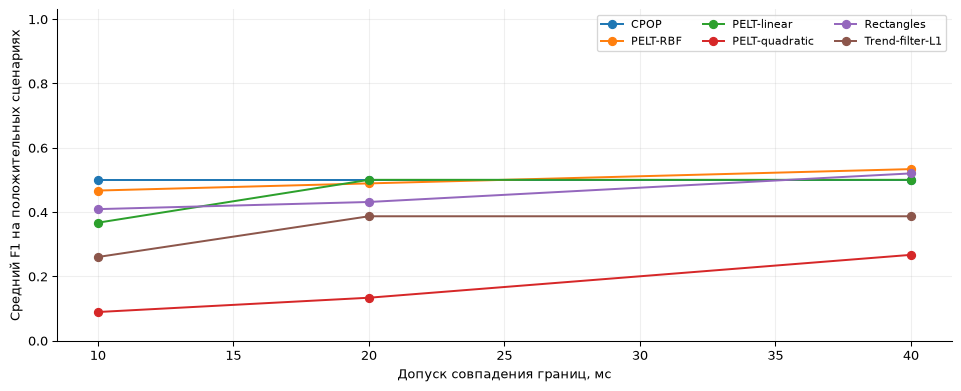

tolerance_ms,10.0,20.0,40.0
method,,,
CPOP,0.500000,0.500000,0.500000
PELT-linear,0.366667,0.500000,0.500000
PELT-quadratic,0.088889,0.133333,0.266667
Trend-filter-L1,0.260000,0.386667,0.386667
PELT-RBF,0.466667,0.488889,0.533333
Rectangles,0.408889,0.431111,0.520000


In [7]:
tolerance_table, tolerance_figure = bench.tolerance_sensitivity(test_cases, test_results, tolerances=(.01, .02, .04))
plt.show()
display(tolerance_table.pivot(index="method", columns="tolerance_ms", values="f1").reindex(bench.METHODS))


## 7. Реальные МЭГ: Excel и MNE sample

Параметры из калибровки переносятся без дополнительного подбора.

**Excel:** все каналы загружаются прежним `load_xlsx_series`, затем выбираются три по минимальному, медианному и максимальному std. Выбор сделан по амплитудному признаку, независимо от результатов детекции. Коды STI101 отображаются как временные маркеры; их смысл не переносится из MNE sample.

**MNE:** прежняя `load_sample_epochs(condition=None)` загружает четыре условия; `select_series` выбирает первую пробу одного исправного градиометра для каждого условия. Используются отдельные пробы, а не усреднения. Сохраняется предобработка загрузчика: MEG/EEG 1–40 Гц, baseline до 0, стандартные проекторы.

Частоты дискретизации отличаются: минимальная длина переводится в отсчёты с округлением вверх, шаг сетки — к ближайшему числу отсчётов. Фактические `min_size`, `jump` и частота сохраняются. В файлах нет истинной разметки разладок: поэтому для реальных рядов F1, precision/recall и ошибки положения **не вычисляются**. Событие предъявления стимула не является разметкой разладки.

In [8]:
real_cases = bench.load_real_cases(DATA_DIR, include_mne=INCLUDE_MNE)
real_metrics, real_results = bench.compare_cases(
    real_cases, selected_parameters, min_duration=MIN_DURATION_S,
    grid_seconds=CANDIDATE_GRID_S, tolerance_seconds=MATCH_TOLERANCE_S,
)
display(scroll_table(real_metrics[[
    "case_id", "method", "n_samples", "sfreq_hz", "min_size", "jump", "n_breaks",
    "elapsed_seconds", "tf_raw_knots", "solver_duality_gap", "residual_acf1", "break_times_s",
]], max_height=480))
display(real_metrics.pivot(index="case_id", columns="method", values="n_breaks").reindex(columns=bench.METHODS))


case_id,method,n_samples,sfreq_hz,min_size,jump,n_breaks,elapsed_seconds,tf_raw_knots,solver_duality_gap,residual_acf1,break_times_s
Excel/MEG0813/low-std,CPOP,2001,1000,30,10,0,1.0772,—,—,0.76713,[]
Excel/MEG0813/low-std,PELT-linear,2001,1000,30,10,0,0.0066418,—,—,0.76713,[]
Excel/MEG0813/low-std,PELT-quadratic,2001,1000,30,10,0,0.0076215,—,—,0.76117,[]
Excel/MEG0813/low-std,Trend-filter-L1,2001,1000,30,10,2,0.033009,2,9.9332e-11,0.75308,"[0.89, 1.52]"
Excel/MEG0813/low-std,PELT-RBF,2001,1000,30,10,0,0.099082,—,—,0.7811,[]
Excel/MEG0813/low-std,Rectangles,2001,1000,30,10,2,0.0036375,—,—,0.7535,"[0.6, 1.41]"
Excel/MEG1543/median-std,CPOP,2001,1000,30,10,0,1.0946,—,—,0.86402,[]
Excel/MEG1543/median-std,PELT-linear,2001,1000,30,10,0,0.0046623,—,—,0.86402,[]
Excel/MEG1543/median-std,PELT-quadratic,2001,1000,30,10,0,0.0072877,—,—,0.86398,[]
Excel/MEG1543/median-std,Trend-filter-L1,2001,1000,30,10,3,0.032723,3,3.3398e-10,0.85128,"[0.26, 0.78, 1.58]"


method,CPOP,PELT-linear,PELT-quadratic,Trend-filter-L1,PELT-RBF,Rectangles
case_id,,,,,,
Excel/MEG0813/low-std,0,0,0,2,0,2
Excel/MEG1543/median-std,0,0,0,3,0,3
Excel/MEG2043/high-std,0,0,0,4,0,1
MNE/auditory/left/MEG 0113/first-trial,1,2,1,9,2,3
MNE/auditory/right/MEG 0113/first-trial,4,3,0,7,3,4
MNE/visual/left/MEG 0113/first-trial,3,2,0,7,3,4
MNE/visual/right/MEG 0113/first-trial,1,3,0,5,3,4


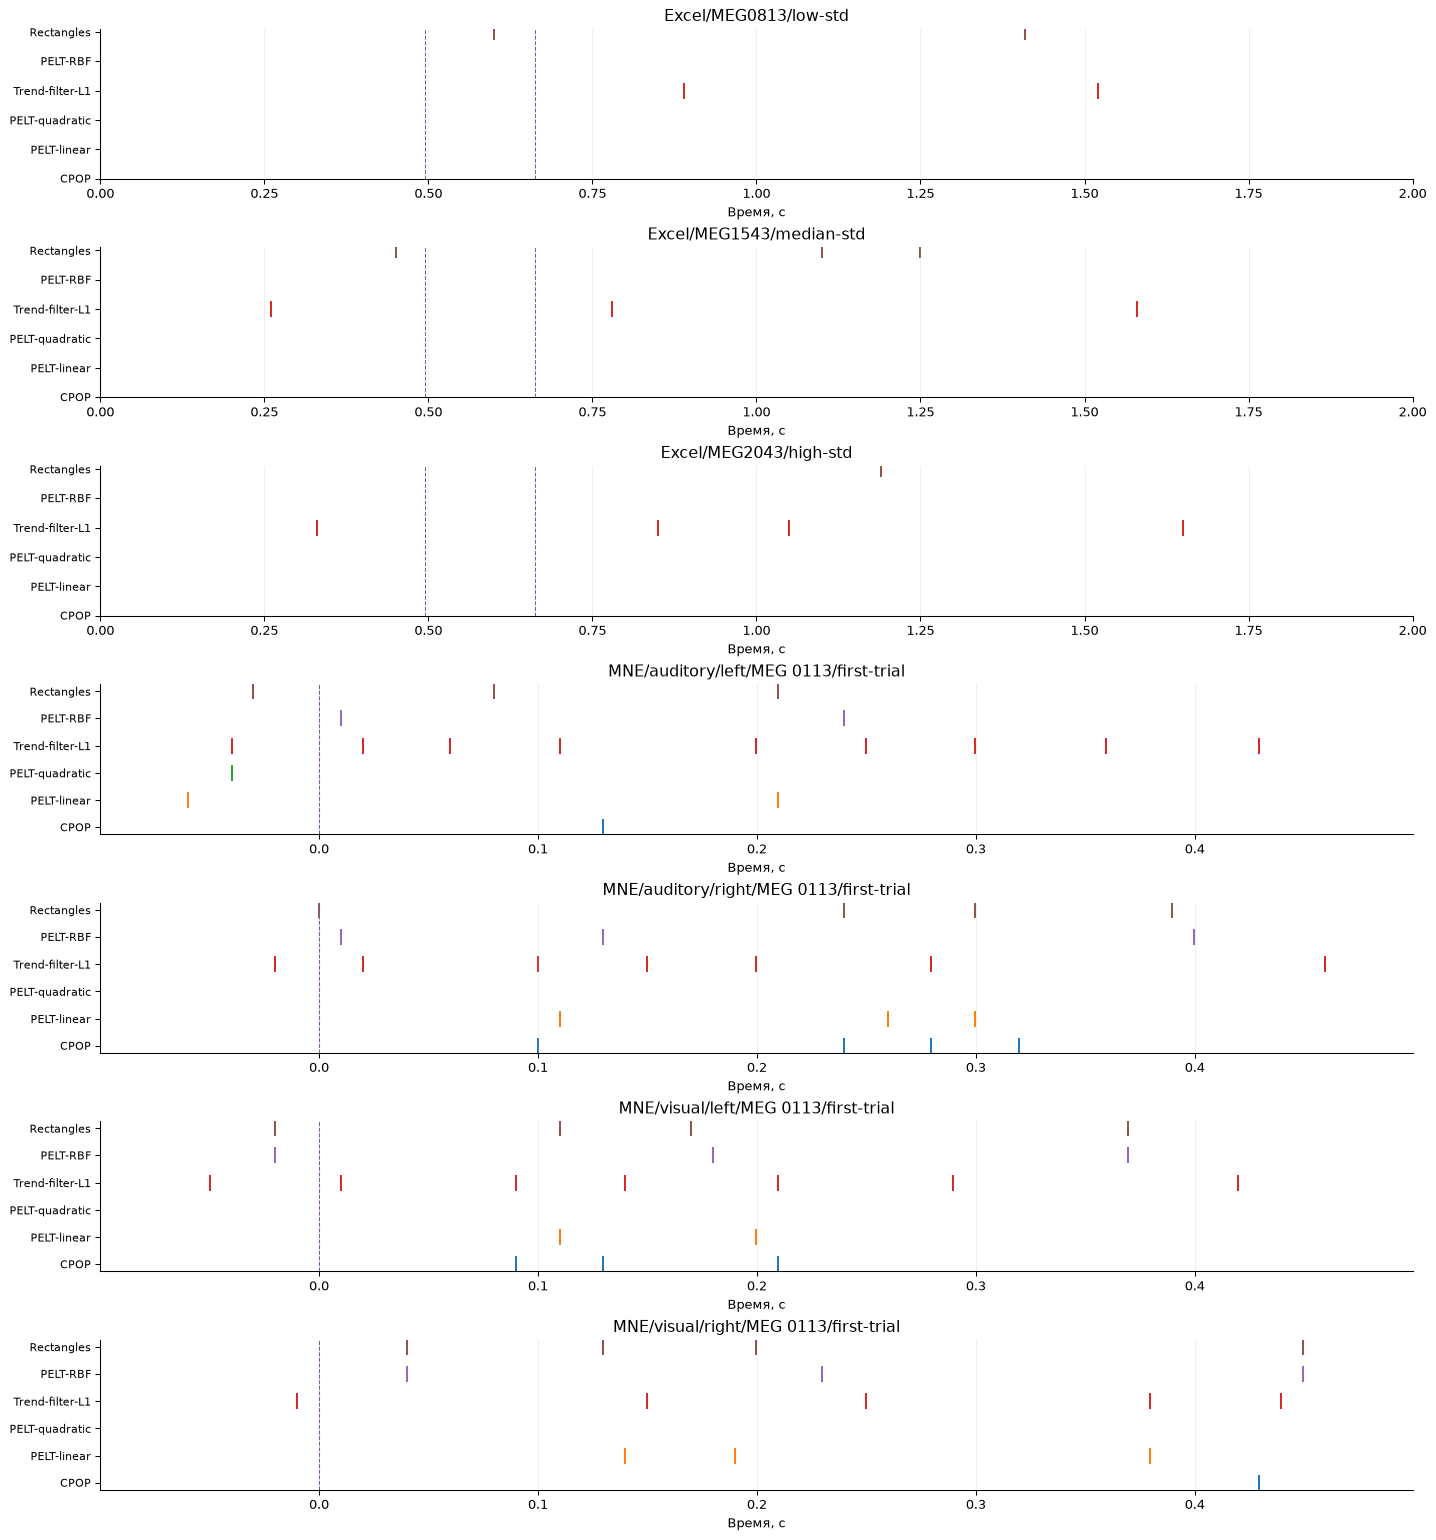

In [9]:
real_raster = bench.plot_real_boundaries(real_cases, real_results)
real_raster.savefig(OUTPUT_DIR / "real_boundaries.png", dpi=130, bbox_inches="tight")
plt.show()


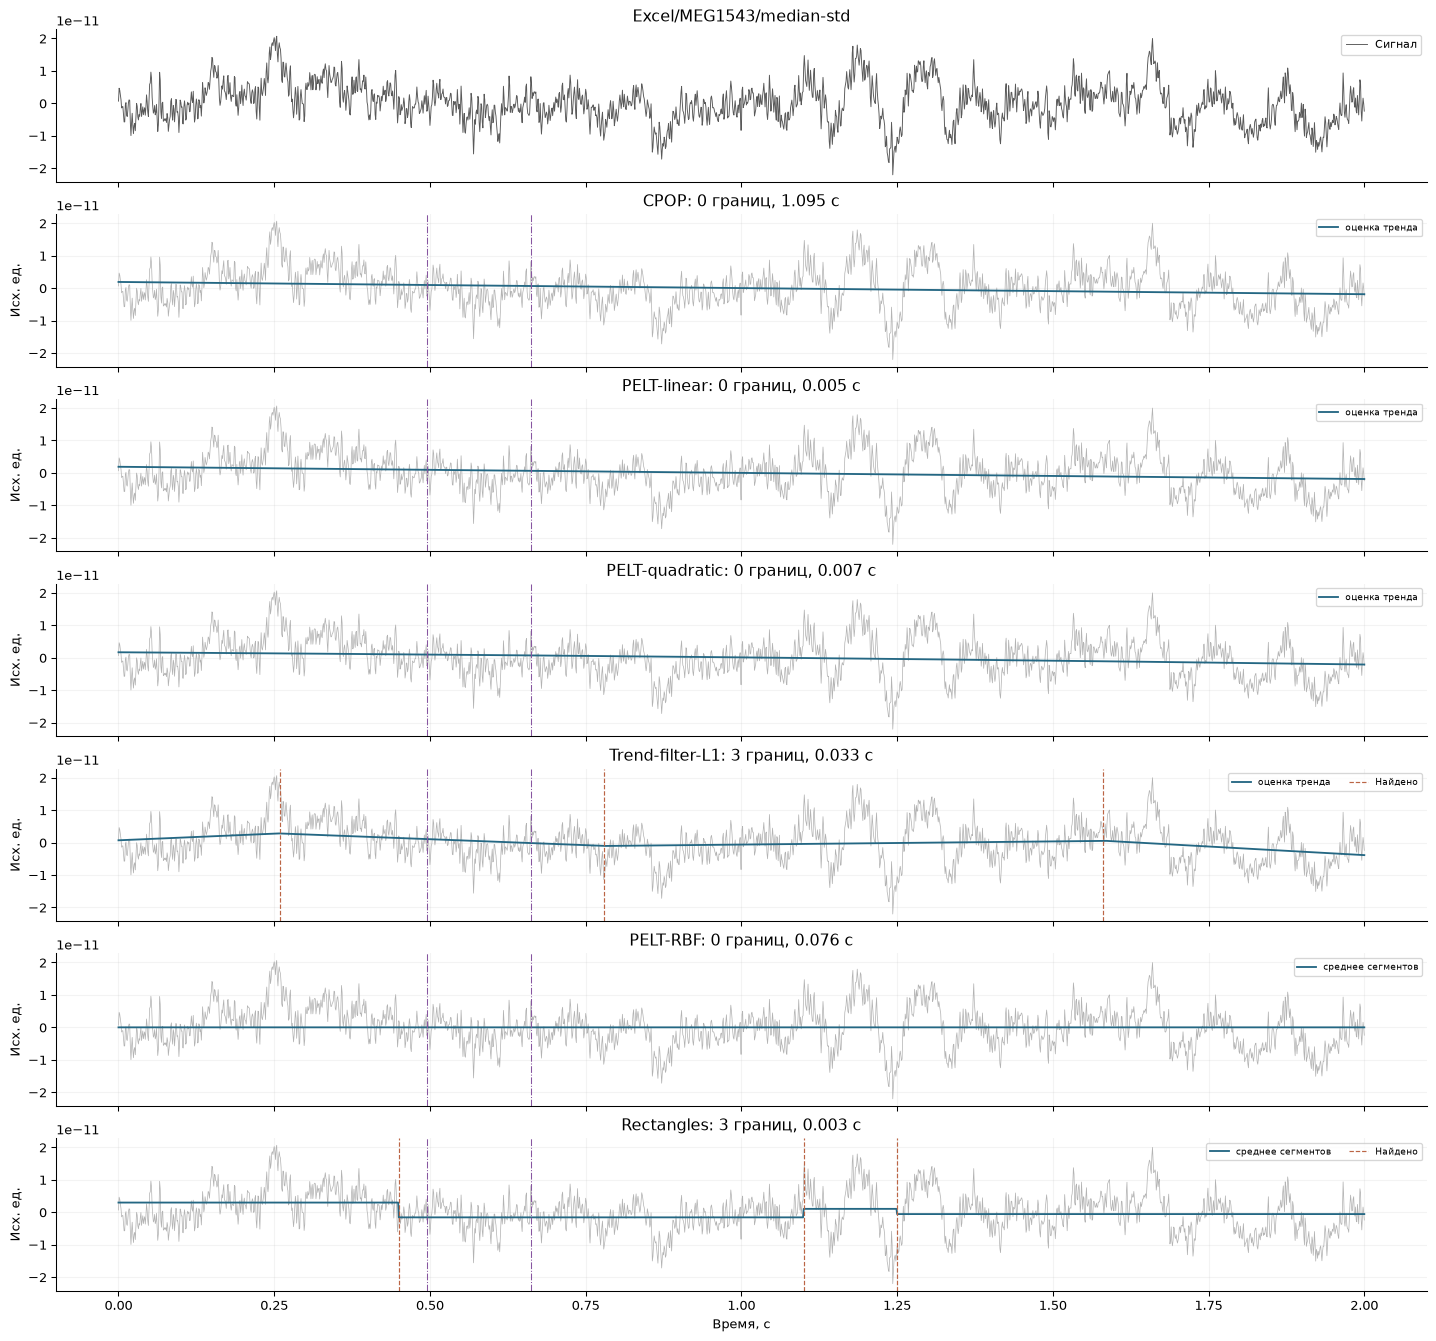

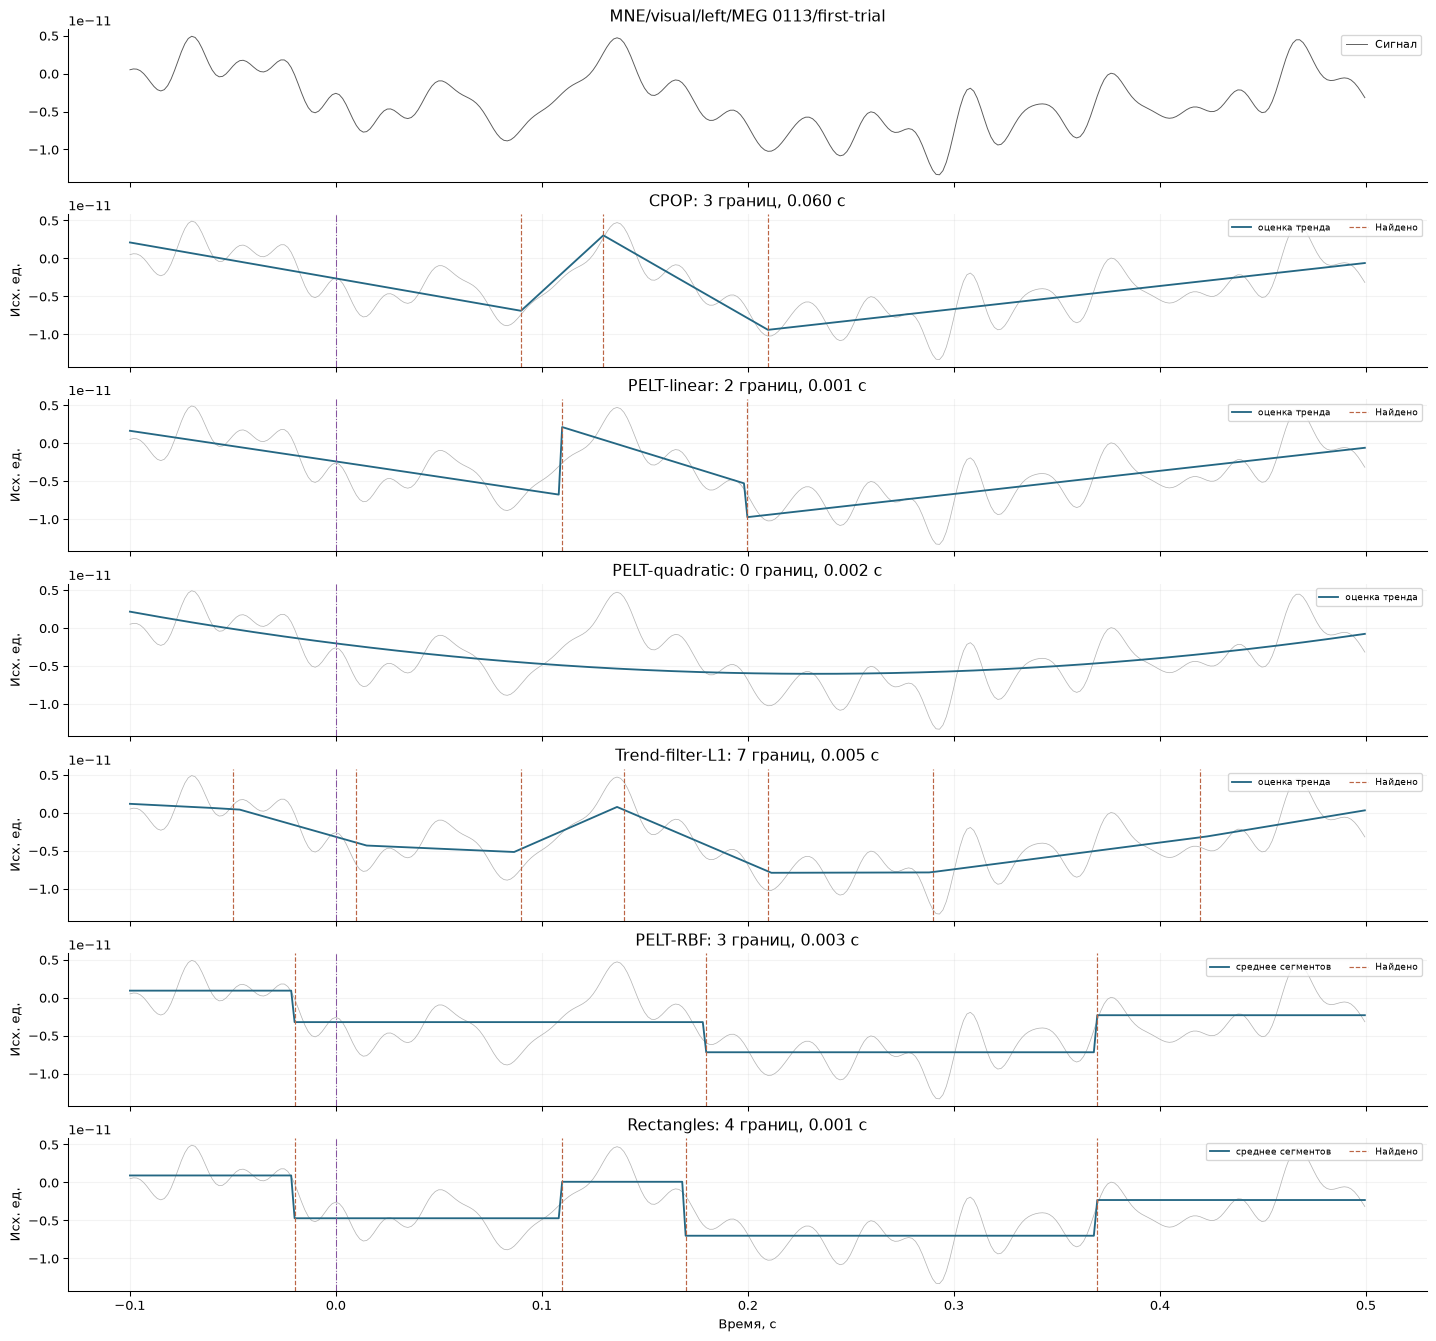

In [10]:
# Подробные кривые: медианный Excel-канал и первая проба visual/left.
excel_case = next(c for c in real_cases if c.source == "Excel" and "median-std" in c.case_id)
bench.plot_case_comparison(excel_case, real_results[excel_case.case_id])
plt.show()
if INCLUDE_MNE:
    mne_case = next(c for c in real_cases if "MNE/visual/left/" in c.case_id)
    bench.plot_case_comparison(mne_case, real_results[mne_case.case_id])
    plt.show()


## 8. Согласованность методов и устойчивость настройки

Матрица ниже — попарное совпадение границ с допуском 20 мс для одного Excel-ряда. **Это согласованность, а не точность.** Два метода могут одинаково реагировать на помеху или на обычный цикл колебания. Значение 1 при двух пустых предсказаниях также не подтверждает отсутствие событий.

Дополнительно удваиваем и уменьшаем вдвое параметр каждого метода на том же ряду. Смотрим число границ и совпадение с фиксированным вариантом. Реальная запись используется только для описания чувствительности: по этой таблице новый параметр не выбирается.

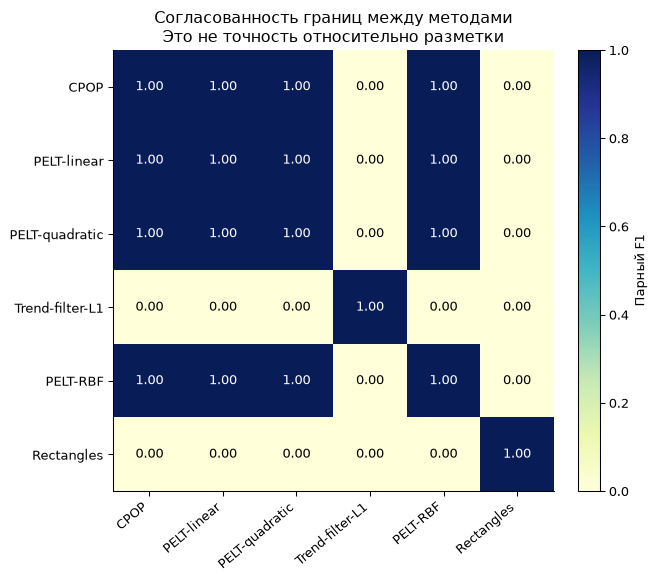

,method,parameter_factor,n_breaks,agreement_with_selected,elapsed_seconds
0,CPOP,0.5,0,1.000000,2.315099
1,CPOP,1.0,0,1.000000,1.165442
2,CPOP,2.0,0,1.000000,0.792967
3,PELT-linear,0.5,3,0.000000,0.004173
4,PELT-linear,1.0,0,1.000000,0.004597
5,PELT-linear,2.0,0,1.000000,0.004829
6,PELT-quadratic,0.5,0,1.000000,0.007198
7,PELT-quadratic,1.0,0,1.000000,0.007193
8,PELT-quadratic,2.0,0,1.000000,0.007205
9,Trend-filter-L1,0.5,5,0.500000,0.030951


In [11]:
bench.boundary_agreement(excel_case, real_results[excel_case.case_id], MATCH_TOLERANCE_S)
plt.show()
stability = bench.parameter_sensitivity(excel_case, selected_parameters, factors=(.5, 1., 2.))
display(stability)


## 9. Диагностика trend filtering

У выпуклого решателя есть две независимые проверки: малый разрыв между прямой и допустимой двойственной задачами и малая невязка стационарности KKT. Они проверяют решение оптимизационной задачи, но не правильность интерпретации её узлов как физиологических разладок.

`tf_raw_knots` — число активных вторых разностей до привязки к сетке и объединения. `n_breaks` — итоговые сообщаемые границы. На графике видно, какие изменения наклона присутствуют в исходной оценке тренда.

,case_id,n_breaks,tf_raw_knots,solver_duality_gap,elapsed_seconds
3,slope/seed1000/rep0,2,3.0,4.821599e-11,0.004175
9,quadratic/seed1000/rep0,3,4.0,3.649926e-10,0.004067
15,mean/seed1000/rep0,4,7.0,8.888210e-11,0.004350
21,variance/seed1000/rep0,0,0.0,3.941292e-15,0.000291
27,ar_slope/seed1000/rep0,3,5.0,7.919686e-11,0.008053
33,noise/seed1000/rep0,0,0.0,1.937339e-14,0.000333
39,spike/seed1000/rep0,0,0.0,1.360023e-14,0.004766
45,oscillation/seed1000/rep0,0,0.0,1.443290e-15,0.000463
51,slope/seed1000/rep1,2,4.0,2.315277e-10,0.004010
57,quadratic/seed1000/rep1,3,4.0,1.979525e-10,0.003890


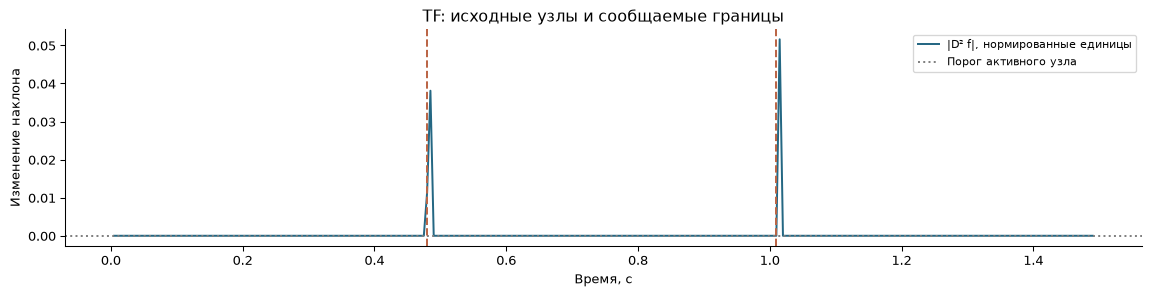

In [12]:
all_metrics = pd.concat([test_metrics, real_metrics], ignore_index=True)
display(all_metrics.loc[all_metrics.method == "Trend-filter-L1", [
    "case_id", "n_breaks", "tf_raw_knots", "solver_duality_gap", "elapsed_seconds"
]].head(12))
example = next(c for c in test_cases if c.scenario == "slope")
tf = test_results[example.case_id]["Trend-filter-L1"]
fig, ax = plt.subplots(figsize=(12, 3), layout="constrained")
ax.plot(example.times[1:-1], np.abs(tf.diagnostics["curvature"]), color="#246783", label="|D² f|, нормированные единицы")
ax.axhline(tf.params["knot_tolerance"], color=".5", ls=":", label="Порог активного узла")
for b in tf.change_points:
    ax.axvline(example.times[b], color="#bb6545", ls="--")
ax.set(xlabel="Время, с", ylabel="Изменение наклона", title="TF: исходные узлы и сообщаемые границы")
ax.legend(fontsize=8)
plt.show()


## 10. Результаты и границы выводов

Ниже перечислены результаты **независимого теста** и описательная сводка реальных примеров. Лидер определяется отдельно для каждого механизма; смешанная средняя оценка зависит от того, какие изменения считаются целевыми и как часто они встречаются.

In [13]:
display(Markdown(bench.comparison_findings(overall, by_scenario, real_metrics)))


**slope:** наибольший средний тестовый F1=1.00 у CPOP, PELT-linear, Trend-filter-L1.

**quadratic:** наибольший средний тестовый F1=0.44 у PELT-RBF.

**mean:** наибольший средний тестовый F1=1.00 у PELT-RBF, Rectangles.

**variance:** наибольший средний тестовый F1=1.00 у PELT-RBF.

**ar_slope:** наибольший средний тестовый F1=1.00 у CPOP.

**Отрицательные контроли:** минимальная средняя частота ложных границ — 0.00/с у CPOP. Этот показатель нужно читать вместе с F1 на рядах с настоящими изменениями: отказ от любых границ тоже убирает ложные тревоги.

**Excel, число найденных границ:** CPOP: 0–0; PELT-linear: 0–0; PELT-quadratic: 0–0; Trend-filter-L1: 2–4; PELT-RBF: 0–0; Rectangles: 1–3. Это результаты фиксированных параметров без разметки.

**MNE, число найденных границ:** CPOP: 1–4; PELT-linear: 2–3; PELT-quadratic: 0–1; Trend-filter-L1: 5–9; PELT-RBF: 2–3; Rectangles: 3–4. Это результаты фиксированных параметров без разметки.

Калибровка отражает выбранную смесь восьми синтетических механизмов. На реальных данных нет оценки точности; большое число совпадающих границ между методами также не заменяет аннотации. Проверка ручной разметкой и устойчивость к предобработке остаются следующим этапом.

Практическая интерпретация:

- CPOP оценивает непрерывный тренд с изломами; на гладкой кривизне дополнительные линейные куски могут быть способом аппроксимации, а не отдельными режимами.
- Регрессионный PELT выбирает границы вместе с независимыми полиномами. Квадратичный вариант гибче, но может объединять несколько размеченных изменений или иметь неоднозначное положение стыка.
- Trend filtering оптимизирует качество кривой и L1-штраф на производную. Расположение его узлов может быть смещено; извлечение и объединение узлов — отдельная часть детектора.
- RBF реагирует на изменения распределения амплитуд, а прямоугольники — на диапазон значений. Эти критерии могут быть предпочтительнее для смены разброса, но это ещё не доказательство качества на реальных записях.
- Автокорреляция и стационарная ритмика могут приводить к ложным границам у всех подходов. Значения штрафов, выученные на коротких синтетических рядах, требуют независимой проверки на размеченных МЭГ.

Для следующего этапа нужны аннотированные разладки и разделение настройки/проверки по пробам, а при наличии нескольких участников — по участникам. Полезно также сравнить заранее фиксированные варианты выделения тренда, сохраняя одинаковую предобработку для всех методов.

## 11. Экспорт и повторное использование

Сохраняем калибровочные оценки, все тестовые метрики, описательные метрики реальных рядов и предсказанные границы с параметрами/диагностикой. Manifest фиксирует версии, идентификаторы наборов и SHA-256 использованных массивов. CSV содержит цели оптимизации для аудита, но их значения не трактуются как общая шкала качества.

Отдельные функции: `segment_cpop`, `segment_regression(degree=1/2)`, `segment_trend_filter`, `segment_rbf`. Все возвращают `BreakResult`: `breakpoints` с последним `n`, `change_points` без него, `fit` в исходных единицах, собственную целевую функцию, параметры и диагностику. Проверка всего набора: `python -m unittest discover -s tests -v` из корня проекта.

In [14]:
combined_results = {**test_results, **real_results}
files = bench.export_comparison(
    OUTPUT_DIR, selected_parameters, calibration_scores, calibration_predictions,
    test_metrics, real_metrics, [*test_cases, *real_cases], combined_results,
)
stability.to_csv(OUTPUT_DIR / "parameter_stability.csv", index=False)
tolerance_table.to_csv(OUTPUT_DIR / "matching_tolerance.csv", index=False)
display(files)
display(Markdown(
    "[Тестовые метрики](breakpoint_comparison/test_metrics.csv) · "
    "[Границы и диагностика](breakpoint_comparison/predictions.json) · "
    "[Manifest](breakpoint_comparison/manifest.json)"
))


,file,size_kb
0,calibration_predictions.csv,102.2
1,calibration_scores.csv,1.3
2,manifest.json,11.3
3,matching_tolerance.csv,0.5
4,parameter_stability.csv,0.8
5,predictions.json,108.7
6,real_boundaries.png,164.4
7,real_descriptive_metrics.csv,8.8
8,synthetic_summary.png,101.1
9,test_metrics.csv,26.9


[Тестовые метрики](breakpoint_comparison/test_metrics.csv) · [Границы и диагностика](breakpoint_comparison/predictions.json) · [Manifest](breakpoint_comparison/manifest.json)

## Источники

- [Fearnhead, Maidstone, Letchford: Detecting changes in slope with an L0 penalty](https://www.lancaster.ac.uk/staff/letchfoa/articles/cpop.pdf): CPOP, рекурсия квадратичных функций и функциональное отсечение.
- [Tibshirani: Adaptive piecewise polynomial estimation via trend filtering](https://arxiv.org/abs/1304.2986): L1-регуляризация дискретных производных.
- [Ruptures: регрессионная стоимость](https://centre-borelli.github.io/ruptures-docs/user-guide/costs/costlinear/), [RBF-стоимость](https://centre-borelli.github.io/ruptures-docs/user-guide/costs/costrbf/).
- [Clarabel: постановка и решение квадратичных задач](https://clarabel.org/stable/python/getting_started_py/).
- Исходный прямоугольный метод и его параметризация описаны в `rectangle_demo.ipynb`; структура и свойства данных — в `eda.ipynb`.

Тесты сравнивают CPOP с полным перебором и совместным МНК сплайна, обе PELT-стоимости — с независимыми вычислениями и перебором, trend filtering — с независимым решением ограниченной двойственной задачи. Дополнительно проверяются масштабы МЭГ, постоянные ряды, сетка, минимальная длина и взаимно однозначное сопоставление границ.